# Klasifikasi Kenaikan Harga Produsen Padi Bulan Berikutnya di 16 Negara Asia Periode 2022–2024

Kelompok **17 — Sop Pak Min Klaten**, kelas **IF-B**, UPN “Veteran” Yogyakarta.

| Nama | NIM | Kelas | Kontribusi bersama |
|---|---|---|---|
| Ghazian Muhammad Al Faruq | 123240013 | IF-B | Perumusan masalah, penelusuran sumber, audit data, EDA, dan penulisan penjelasan. |
| M. Affan Musyafa' | 123240155 | IF-B | Perumusan masalah, penelusuran sumber, audit data, EDA, dan penulisan penjelasan. |
| Firraz Muhammad Raihan Daffa | 123240170 | IF-B | Perumusan masalah, penelusuran sumber, audit data, EDA, dan penulisan penjelasan. |
| Jauza Ilham Mahardhika Putra | 123240174 | IF-B | Perumusan masalah, penelusuran sumber, audit data, EDA, dan penulisan penjelasan. |

**Cakupan saat ini: Business Understanding dan Data Understanding.** Bagian pertama menjelaskan masalah dan rancangan penelitian. Bagian kedua memuat sumber data, kamus data, pemeriksaan kualitas, EDA, serta audit awal fitur dan pembagian waktu. Seluruh anggota mengerjakan tahap ini bersama dengan kontribusi setara.

Notebook dijalankan menggunakan **Python 3.13.12**. Pilih kernel dengan versi tersebut, lalu jalankan seluruh sel dari awal. Tabel dan grafik berasal dari CSV asli yang disertakan dalam repo. Pelatihan model dan evaluasi kinerjanya masih menjadi tahap berikutnya.


# Business Understanding

## 1. Judul dan tujuan penelitian

Penelitian ini mengkaji apakah riwayat harga dapat membantu mengenali kenaikan harga nominal produsen padi **satu bulan ke depan**. Metode yang dipilih adalah **klasifikasi biner**. Kelas 1 berarti harga naik, sedangkan kelas 0 berarti harga turun atau tetap. Penelitian belum bertujuan memperkirakan nilai harga atau besarnya persentase kenaikan.

Satu contoh analisis mewakili **satu negara pada bulan acuan t**. Cakupan penelitian adalah 16 negara Asia yang memiliki observasi terpilih dalam snapshot FAOSTAT pada 2022–2024. Hasilnya tidak mewakili seluruh Asia.

Komoditas mengikuti label sumber `Rice`, dengan `Item Code=27`. Harga yang digunakan adalah `Producer Price (LCU/tonne)`, yaitu harga produsen dalam mata uang lokal per ton. Istilah padi digunakan sesuai cakupan tersebut. Perbedaan bentuk dan mutu komoditas yang dilaporkan antarnegara tetap menjadi keterbatasan.


## 2. Masalah dan calon pengguna

Koperasi petani padi dan analis kebijakan harga pangan berpotensi membutuhkan ringkasan arah perubahan harga pada tingkat produsen. Namun, manfaat pola harga historis dibandingkan tebakan sederhana belum diketahui.

**Pertanyaan utama:** apakah informasi harga sampai bulan t dapat membantu mengklasifikasikan kenaikan harga pada bulan t+1?

Pertanyaan ini akan dijawab dengan membandingkan model dengan baseline, memeriksa negara yang kurang terwakili, serta membahas risiko alarm palsu dan kenaikan yang terlewat.

Stakeholder tersebut merupakan calon pengguna analisis. Belum ada wawancara atau validasi kebutuhan dari mereka. FAO berperan sebagai penerbit data dan bukan sebagai mitra atau pemberi persetujuan proyek.


## 3. Tujuan SMART

1. **Pada 26 Oktober 2026**, menyelesaikan Business Understanding dan Data Understanding yang dapat diperiksa ulang. Ukurannya adalah tersedianya masalah, stakeholder, tujuan, metrik, asumsi, risiko, sumber dan kamus data, audit kualitas, serta EDA dengan penjelasan.
2. **Pada 30 Oktober 2026**, menyiapkan tahapan awal sesuai panduan, dari pengumpulan data sampai cleaning dan preprocessing, termasuk alasan pembuatan serta pemilihan sedikitnya empat fitur. Versi ini sudah menyediakan audit kalender, fitur, dan pembagian waktu. Pemilihan transformasi untuk model akan dilanjutkan berdasarkan data latih.
3. **Sebelum 22 November 2026**, membandingkan Regresi Logistik berregularisasi L2 dan Random Forest dengan dua baseline pada pembagian waktu yang tetap. Hasil yang dilaporkan mencakup macro-F1, balanced accuracy, recall dan precision kenaikan, serta keterbatasan per negara.

Keberhasilan pengerjaan dinilai dari alur yang dapat dijalankan ulang dan evaluasi yang benar. Peningkatan kinerja terhadap baseline masih harus diuji. Hasil tanpa peningkatan tetap perlu dilaporkan.


## 4. Metode, target, dan model yang dipilih

Harga negara c pada bulan t ditulis sebagai P(c,t). Metode yang digunakan adalah **klasifikasi biner** dengan target pada bulan kalender berikutnya di negara yang sama:

- `target=1` jika P(c,t+1) > P(c,t).
- `target=0` jika P(c,t+1) ≤ P(c,t), termasuk harga tetap.
- Target tidak tersedia jika salah satu harga tidak tercatat.

**Model utama yang dipilih adalah Regresi Logistik dengan regularisasi L2**, menggunakan algoritma optimisasi **L-BFGS**. Pilihan ini mempertimbangkan data latih yang hanya memiliki 120 contoh, jumlah fitur yang sedikit, dan korelasi beberapa fitur harga yang cukup tinggi. Regularisasi membantu membatasi kompleksitas model. Koefisiennya juga dapat diperiksa untuk memahami hubungan fitur dengan kecenderungan kelas, tanpa menyimpulkan sebab-akibat.

Empat fitur harga akan distandardisasi dengan `StandardScaler` yang dipelajari hanya dari data latih. Bulan diperlakukan sebagai informasi kalender dan penanganannya ditetapkan pada tahap preprocessing. Rancangan awal memakai `solver='lbfgs'` dan `max_iter=1000`. Kekuatan regularisasi dipilih dari `C=0.1`, `C=1`, atau `C=10` melalui data validasi. Ambang awal probabilitas adalah 0,5.

**Random Forest digunakan sebagai model pembanding** untuk memeriksa apakah hubungan nonlinier dan interaksi fitur memberikan hasil lebih baik. Random Forest menggunakan `random_state=42`. Kedalaman pohon dan jumlah minimum contoh pada daun akan dibatasi agar model tidak sekadar menghafal sampel latih yang kecil.

Dua baseline tetap digunakan, yaitu **kelas mayoritas data latih** dan **persistensi arah**, yang memprediksi naik jika perubahan harga satu bulan terakhir positif. Semua input hanya memakai informasi sampai t. Negara dan tanggal berfungsi sebagai identitas panel.

Regresi Logistik merupakan pilihan utama pada rancangan saat ini. **Model dengan kinerja terbaik belum dapat ditetapkan sebelum pengujian.** Penetapan model akhir menggunakan macro-F1 pada validasi, kemudian model dikunci sebelum dinilai pada data uji. Notebook ini belum melatih model atau menghasilkan metrik kinerjanya.

Rujukan algoritma: [Regresi Logistik](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) dan [Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forest).


## 5. Ukuran keberhasilan

| Metrik | Alasan penggunaan |
|---|---|
| Macro-F1, metrik utama | Memberikan bobot yang sama pada kelas naik dan tidak naik. |
| Balanced accuracy | Merata-ratakan recall kedua kelas ketika komposisinya berbeda. |
| Recall kenaikan | Menunjukkan bagian kenaikan aktual yang berhasil dikenali. |
| Precision kenaikan | Menunjukkan bagian sinyal kenaikan yang benar, sehingga alarm palsu dapat dinilai. |
| Confusion matrix dan accuracy | Memperlihatkan jenis kesalahan dan ringkasan ketepatan sebagai pelengkap. |

Baseline dan model harus dinilai pada observasi yang sama. Hasil akan disajikan secara keseluruhan dan per negara dengan jumlah contohnya. Manfaat prediktif awal didukung jika macro-F1 model lebih tinggi daripada masing-masing baseline, sehingga selisihnya harus lebih dari nol. Ambang manfaat operasional belum divalidasi oleh stakeholder. Macro-F1 bukan persentase prediksi yang benar dan bukan probabilitas harga akan naik.


## 6. Asumsi dan batasan

1. Data berisi harga agregat nasional pada 16 negara terpilih. Data ini tidak menggantikan harga yang diterima setiap petani atau koperasi setempat.
2. Satuan `LCU/tonne` berbeda mata uang antarnegara. Level harganya tidak dibandingkan secara langsung. Perubahan relatif tetap dapat dipengaruhi inflasi atau perubahan rezim mata uang.
3. CSV memuat bulan referensi, tetapi tidak memuat tanggal publikasi dan riwayat revisi. Evaluasi nantinya bersifat retrospektif dan bergantung pada ketersediaan harga bulan t.
4. Bulan yang tidak tercatat tidak diisi dengan nol. Kalender harus dilengkapi sebelum menghitung lag dan rolling agar dua observasi yang berjarak jauh tidak dianggap berurutan.
5. Pembagian data mengikuti tanggal global. Transformasi dan pemilihan fitur dipelajari dari data latih, sedangkan parameter dipilih melalui data validasi.
6. Negara yang muncul pada validasi atau uji dapat tidak hadir pada data latih. Cakupan dan jumlah contoh tiap negara perlu dilaporkan.
7. Data tidak memuat biaya simpan, biaya produksi, stok, cuaca, atau mutu gabah individu. Penelitian ini tidak menjelaskan sebab-akibat dan tidak menjadi dasar langsung untuk menyarankan penundaan penjualan.


## 7. Risiko, etika, dan mitigasi

| Risiko | Dampak | Mitigasi |
|---|---|---|
| Cakupan negara dan tahun tidak merata | Negara dengan data lengkap lebih dominan. | Tampilkan cakupan tiap negara dan batasi generalisasi. |
| Kebocoran informasi masa depan | Evaluasi terlihat terlalu baik. | Gunakan kalender bulanan, fitur sampai t, target t+1, dan pembagian waktu dengan pemeriksaan batas target. |
| Salah membaca harga | Harga produsen dianggap harga konsumen atau harga riil. | Jelaskan definisi farm gate, satuan, dan sifat nominal harga. |
| Alarm palsu atau kenaikan terlewat | Ringkasan arah dapat menyesatkan calon pengguna. | Laporkan precision, recall, confusion matrix, dan batas penggunaan. |
| Atribusi atau penggunaan data tidak sesuai | Hak penerbit tidak dijelaskan atau muncul kesan dukungan FAO. | Cantumkan FAO, snapshot, tautan, lisensi, dan ketentuan tambahannya. |
| Jeda publikasi dan revisi tidak diketahui | Backtest belum tentu sesuai penggunaan langsung. | Jelaskan sifat retrospektif dan periksa ketersediaan data sebelum penerapan nyata. |

Data penelitian berupa harga agregat publik. Nama dan NIM hanya menjadi identitas penyusun. Tidak digunakan data pribadi petani, data sintetis, atau harga tambahan yang dikarang.


## 8. Nilai penggunaan

Hasil penelitian diharapkan menjadi bahan kajian pemantauan arah harga bagi koperasi dan analis kebijakan. Manfaat yang diuji adalah tambahan informasi dibandingkan aturan sederhana. Belum ada bukti keuntungan finansial dari model.

Demo tahap akhir direncanakan memuat `negara`, `bulan_acuan`, `arah_prediksi`, dan `label_aktual` jika tersedia. Skor probabilitas hanya akan ditampilkan jika sifat dan keterbatasannya sudah dijelaskan.

Keputusan memakai model perlu mempertimbangkan kinerja, variasi antarnegara, kebutuhan pemeliharaan data, dan konsekuensi kesalahan. Perhitungan laba belum dapat dilakukan karena data biaya tidak tersedia.


## 9. Pemetaan stakeholder dan data

| Stakeholder | Kebutuhan | Data yang relevan | Batas penggunaan |
|---|---|---|---|
| Koperasi petani padi, calon pengguna | Ringkasan arah harga produsen | Negara, bulan, riwayat harga, dan arah bulan berikutnya | Harga nasional tidak menggantikan harga lokal dan biaya simpan. |
| Analis kebijakan harga pangan, calon pengguna | Perbandingan pola dan cakupan antarnegara | Kode M49, tanggal, perubahan relatif, dan flag sumber | Tidak mendukung klaim sebab-akibat atau representasi seluruh Asia. |
| Kelompok peneliti | Analisis yang dapat dijalankan ulang | CSV asli, checksum, definisi fitur, dan protokol waktu | Setiap proses perlu dipahami dan rencana harus dibedakan dari hasil. |
| FAO, penerbit data | Atribusi dan interpretasi yang tepat | Metadata komoditas, satuan, flag, dan lisensi | Bukan sponsor atau validator hasil penelitian. |


# Data Understanding

## 10.1 Sumber data, cakupan, dan lisensi

Data berasal dari **FAO, FAOSTAT Producer Prices**. Berkas asli pengguna adalah `Agricultural producer prices (Global, National - Annual, Monthly) - FAOSTAT.csv`. Salinannya disimpan sebagai `data/raw/faostat_rice_producer_prices.csv` tanpa mengubah isi. Snapshot diperoleh pada 15 Oktober 2026 menurut catatan proyek dan diverifikasi ulang pada 26 Oktober 2026.

[FAO menjelaskan](https://www.fao.org/prices/en) harga produsen sebagai harga pada tingkat farm gate atau penjualan pertama. Harga ini berbeda dari harga eceran, harga ekspor, dan indeks harga beras internasional. Satuan yang dipilih adalah mata uang lokal per ton.

Penelitian menggunakan observasi bulanan `Rice`, kode 27, harga `Producer Price (LCU/tonne)` dengan flag `A`, tahun 2022–2024, dan 16 kode M49 Asia yang tercantum di bawah. `A` berarti angka resmi menurut klasifikasi penerbit, bukan jaminan bebas revisi. [Klasifikasi M49 PBB](https://unstats.un.org/unsd/methodology/m49/) digunakan untuk ruang lingkup wilayah. Negara Asia yang tidak memiliki observasi dalam rentang ini tidak disertakan. Rusia tidak disertakan karena berada dalam kelompok statistik Eropa.

FAO. 2026. *FAOSTAT: Producer Prices*. Diakses 15 Oktober 2026. [Portal dataset](https://www.fao.org/faostat/en/#data/PP). Lisensi CC BY 4.0 dengan [ketentuan tambahan basis data FAO](https://www.fao.org/contact-us/terms/db-terms-of-use/en). Tidak ada klaim dukungan atau validasi dari FAO.

Kode berikut memeriksa versi Python, ukuran berkas, dan checksum sebelum membaca data. Pemeriksaan dihentikan jika snapshot berubah, agar hasil lama tidak dipakai untuk data yang berbeda.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import platform
import hashlib

from pathlib import Path
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 14

print('Versi Python:', platform.python_version())
print('Versi pandas:', pd.__version__)
print('Versi NumPy:', np.__version__)

if platform.python_version() != '3.13.12':
    raise ValueError('Pilih kernel Python 3.13.12 sebelum menjalankan notebook.')


Versi Python: 3.13.12
Versi pandas: 2.3.3
Versi NumPy: 2.5.3


In [3]:
data_path = 'data/raw/faostat_rice_producer_prices.csv'
df = pd.read_csv(
    data_path,
    dtype={'faostat': 'string', 'M49 Code': 'string', 'Item Code': 'string'}
)

df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d')
display(df.head())
print('Ukuran data (baris, kolom):', df.shape)
print('Jumlah negara:', df['Country'].nunique())
print('Periode awal:', df['date'].min())
print('Periode akhir:', df['date'].max())
df.info()


,faostat,M49 Code,Country,Item Code,Item,year,Months,Producer Price (LCU/tonne),Producer Price (LCU/tonne) flag,Producer Price (SLC/tonne),Producer Price (SLC/tonne) flag,Producer Price (USD/tonne),Producer Price (USD/tonne) flag,Producer Price Index (2014–2016 = 100),Producer Price Index (2014–2016 = 100) flag,Frequency,date
0,184,646,Rwanda,27,Rice,2010,January,624859.0,A,NaN,NaN,NaN,NaN,NaN,NaN,Monthly,2010-01-01
1,184,646,Rwanda,27,Rice,2010,February,619250.0,A,NaN,NaN,NaN,NaN,NaN,NaN,Monthly,2010-02-01
2,184,646,Rwanda,27,Rice,2010,March,615947.0,A,NaN,NaN,NaN,NaN,NaN,NaN,Monthly,2010-03-01
3,184,646,Rwanda,27,Rice,2010,April,610208.0,A,NaN,NaN,NaN,NaN,NaN,NaN,Monthly,2010-04-01
4,184,646,Rwanda,27,Rice,2010,May,600997.0,A,NaN,NaN,NaN,NaN,NaN,NaN,Monthly,2010-05-01


Ukuran data (baris, kolom): (5341, 17)
Jumlah negara: 73
Periode awal: 2010-01-01 00:00:00
Periode akhir: 2025-01-01 00:00:00
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5341 entries, 0 to 5340
Data columns (total 17 columns):
 #   Column                                       Non-Null Count  Dtype         
---  ------                                       --------------  -----         
 0   faostat                                      5341 non-null   string        
 1   M49 Code                                     5341 non-null   string        
 2   Country                                      5341 non-null   object        
 3   Item Code                                    5341 non-null   string        
 4   Item                                         5341 non-null   object        
 5   year                                         5341 non-null   int64         
 6   Months                                       5341 non-null   object        
 7   Producer Price (LCU/tonne)       

In [4]:
# Snapshot diperiksa agar angka laporan dapat dihitung ulang dari data yang sama.
expected_hash = '5f6470bc3e1284340aaa1022f032bdb8fb49c9aaf059054b41d19e3790636b76'
dataset_hash = hashlib.sha256(Path(data_path).read_bytes()).hexdigest()

if dataset_hash != expected_hash:
    raise ValueError('Snapshot dataset berubah. Periksa ulang hasil analisis.')

print('Komoditas:', df['Item'].unique())
print('Kode komoditas:', df['Item Code'].unique())
print('Frekuensi:', df['Frequency'].unique())

assert df['Item'].eq('Rice').all()
assert df['Item Code'].eq('27').all()
assert df['Frequency'].eq('Monthly').all()
assert df['date'].dt.year.eq(df['year']).all()


Komoditas: ['Rice']
Kode komoditas: <StringArray>
['27']
Length: 1, dtype: string
Frekuensi: ['Monthly']


Berkas ekspor memuat **5.341 baris, 17 kolom, dan 73 negara** pada Januari 2010–Januari 2025. Angka ini merupakan cakupan berkas yang digunakan, bukan seluruh isi basis data FAOSTAT. Kolom `date` menandai awal bulan referensi, bukan tanggal transaksi atau publikasi.

## 10.2 Skema, kamus data, dan seleksi penelitian

Kode wilayah dan komoditas dibaca sebagai teks agar identitas dan nol di depan kode tidak hilang. Kolom harga dibaca sebagai numerik. Tabel berikut menjelaskan seluruh kolom sumber beserta tipe, satuan, dan kegunaannya.


In [5]:
units = [
    'ID wilayah', 'Kode wilayah', 'Nama negara', 'Kode komoditas',
    'Nama komoditas', 'Tahun', 'Bulan', 'LCU/tonne', 'Status',
    'SLC/tonne', 'Status', 'USD/tonne', 'Status', 'Indeks',
    'Status', 'Frekuensi', 'Awal bulan'
]

descriptions = [
    'Identitas wilayah internal FAOSTAT, bukan besaran harga.',
    'Kode M49 tiga digit untuk memilih negara.',
    'Nama negara sesuai label sumber.',
    'Kode 27 untuk Rice.',
    'Rice, digunakan sebagai padi dalam cakupan penelitian.',
    'Tahun referensi observasi.',
    'Nama bulan referensi.',
    'Harga nominal produsen dalam mata uang lokal per ton.',
    'A berarti angka resmi menurut penerbit.',
    'Harga dalam mata uang lokal standar, kosong pada ekspor ini.',
    'Flag ukuran SLC, kosong pada ekspor ini.',
    'Harga dolar AS per ton, kosong pada ekspor ini.',
    'Flag harga USD, kosong pada ekspor ini.',
    'Indeks harga produsen, kosong pada ekspor ini.',
    'Flag indeks harga, kosong pada ekspor ini.',
    'Monthly berarti observasi bulanan.',
    'Tanggal representatif bulan, bukan tanggal publikasi.'
]

data_dictionary = pd.DataFrame({
    'Kolom': df.columns,
    'Tipe data': df.dtypes.astype(str).to_numpy(),
    'Satuan atau peran': units,
    'Keterangan': descriptions
})
display(data_dictionary)


,Kolom,Tipe data,Satuan atau peran,Keterangan
0,faostat,string,ID wilayah,"Identitas wilayah internal FAOSTAT, bukan besa..."
1,M49 Code,string,Kode wilayah,Kode M49 tiga digit untuk memilih negara.
2,Country,object,Nama negara,Nama negara sesuai label sumber.
3,Item Code,string,Kode komoditas,Kode 27 untuk Rice.
4,Item,object,Nama komoditas,"Rice, digunakan sebagai padi dalam cakupan pen..."
5,year,int64,Tahun,Tahun referensi observasi.
6,Months,object,Bulan,Nama bulan referensi.
7,Producer Price (LCU/tonne),float64,LCU/tonne,Harga nominal produsen dalam mata uang lokal p...
8,Producer Price (LCU/tonne) flag,object,Status,A berarti angka resmi menurut penerbit.
9,Producer Price (SLC/tonne),float64,SLC/tonne,"Harga dalam mata uang lokal standar, kosong pa..."


In [6]:
asia_codes = [
    '050', '064', '096', '144', '156', '360', '392', '398',
    '410', '417', '586', '608', '704', '764', '792', '860'
]
price_column = 'Producer Price (LCU/tonne)'
flag_column = 'Producer Price (LCU/tonne) flag'

df_selected = df[
    df['M49 Code'].str.zfill(3).isin(asia_codes)
    & df['year'].between(2022, 2024)
    & df[flag_column].eq('A')
].copy()

df_selected['m49'] = df_selected['M49 Code'].str.zfill(3)
df_selected = df_selected.sort_values(['Country', 'date']).reset_index(drop=True)

display(df_selected[['Country', 'm49', 'date', price_column]].head())
print('Observasi terpilih:', len(df_selected))
print('Negara terpilih:', df_selected['Country'].nunique())


,Country,m49,date,Producer Price (LCU/tonne)
0,Bangladesh,050,2022-01-01,26940.0
1,Bangladesh,050,2022-02-01,27960.0
2,Bangladesh,050,2022-03-01,28140.0
3,Bangladesh,050,2022-04-01,28430.0
4,Bangladesh,050,2022-05-01,22815.0


Observasi terpilih: 511
Negara terpilih: 16


Seleksi menghasilkan **511 observasi asli dari 16 negara**. Kolom alternatif SLC, USD, dan indeks harga beserta flag-nya tidak digunakan karena seluruh nilainya kosong pada ekspor ini. Kolom ID dan metadata yang konstan tidak dianggap sebagai fitur harga yang independen.

## 10.3 Kualitas data dan kesiapan analisis

Pemeriksaan membedakan nilai kosong dalam baris yang tersedia dengan **bulan yang tidak memiliki baris sama sekali**. Pemeriksaan ini juga menilai duplikasi dan harga yang tidak masuk akal secara dasar. Tidak ada nilai yang diperbaiki atau dihapus secara otomatis.


In [7]:
print('Nilai kosong pada setiap kolom sumber:')
display(df.isnull().sum().rename('Nilai kosong').to_frame())

quality_summary = pd.DataFrame({
    'Pemeriksaan': [
        'Duplikat seluruh baris sumber',
        'Duplikat negara-bulan sumber',
        'Duplikat negara-bulan terpilih',
        'Harga LCU kosong pada subset',
        'Harga LCU nol atau negatif pada subset'
    ],
    'Jumlah': [
        df.duplicated().sum(),
        df.duplicated(['M49 Code', 'date']).sum(),
        df_selected.duplicated(['m49', 'date']).sum(),
        df_selected[price_column].isnull().sum(),
        df_selected[price_column].le(0).sum()
    ]
})
display(quality_summary)


Nilai kosong pada setiap kolom sumber:


,Nilai kosong
faostat,0
M49 Code,0
Country,0
Item Code,0
Item,0
year,0
Months,0
Producer Price (LCU/tonne),0
Producer Price (LCU/tonne) flag,0
Producer Price (SLC/tonne),5341


,Pemeriksaan,Jumlah
0,Duplikat seluruh baris sumber,0
1,Duplikat negara-bulan sumber,0
2,Duplikat negara-bulan terpilih,0
3,Harga LCU kosong pada subset,0
4,Harga LCU nol atau negatif pada subset,0


In [8]:
# Kalender dibuat per negara. Bulan kosong tetap NaN dan tidak diisi harga nol.
country_list = sorted(df_selected['Country'].unique())
calendar = pd.date_range('2022-01-01', '2024-12-01', freq='MS')
calendar_data = []

for country in country_list:
    country_data = df_selected[df_selected['Country'] == country]
    country_calendar = country_data.set_index('date')[[price_column]].reindex(calendar)
    country_calendar = country_calendar.rename_axis('date').reset_index()
    country_calendar['Country'] = country
    country_calendar['m49'] = country_data['m49'].iloc[0]
    calendar_data.append(country_calendar)

df_calendar = pd.concat(calendar_data, ignore_index=True)

print('Observasi harga asli:', len(df_selected))
print('Kombinasi negara-bulan:', len(df_calendar))
print('Bulan yang tidak tercatat:', df_calendar[price_column].isnull().sum())


Observasi harga asli: 511
Kombinasi negara-bulan: 576
Bulan yang tidak tercatat: 65


Enam kolom kosong merupakan tiga ukuran alternatif beserta flag-nya. Harga LCU pada 511 baris terpilih tidak kosong, tidak memiliki duplikasi kunci, dan semuanya positif. Namun, kalender 16 negara × 36 bulan menunjukkan **65 bulan yang tidak tercatat**, atau **11,28%** dari 576 kombinasi.

Penambahan kalender hanya menandai kekosongan. **576 bukan jumlah observasi harga asli.** Gap tidak diisi dengan nol, interpolasi, atau harga buatan. Penyebab tidak tercatatnya suatu bulan belum dapat disimpulkan dari CSV.

## 10.4 EDA cakupan dan keterwakilan negara

Cakupan diperiksa per negara agar ketimpangan periode tidak tertutup oleh jumlah total. Kotak gelap pada grafik berarti ada harga resmi yang tercatat. Kotak abu-abu menunjukkan kombinasi negara-bulan yang tidak tercatat.


In [9]:
coverage_rows = []

for country in country_list:
    country_data = df_selected[df_selected['Country'] == country]
    country_calendar = df_calendar[df_calendar['Country'] == country]

    coverage_rows.append({
        'Negara': country,
        'M49': country_data['m49'].iloc[0],
        'Observasi asli': len(country_data),
        'Bulan tidak tercatat': country_calendar[price_column].isnull().sum(),
        'Awal': country_data['date'].min().strftime('%Y-%m'),
        'Akhir': country_data['date'].max().strftime('%Y-%m'),
        'Harga berbeda': country_data[price_column].nunique()
    })

country_coverage = pd.DataFrame(coverage_rows)
display(country_coverage)


,Negara,M49,Observasi asli,Bulan tidak tercatat,Awal,Akhir,Harga berbeda
0,Bangladesh,050,24,12,2022-01,2023-12,24
1,Bhutan,064,36,0,2022-01,2024-12,36
2,Brunei Darussalam,096,36,0,2022-01,2024-12,1
3,"China, mainland",156,36,0,2022-01,2024-12,30
4,Indonesia,360,24,12,2022-01,2024-12,24
5,Japan,392,36,0,2022-01,2024-12,28
6,Kazakhstan,398,31,5,2022-01,2024-12,31
7,Kyrgyzstan,417,36,0,2022-01,2024-12,36
8,Pakistan,586,12,24,2022-01,2022-12,12
9,Philippines,608,36,0,2022-01,2024-12,36


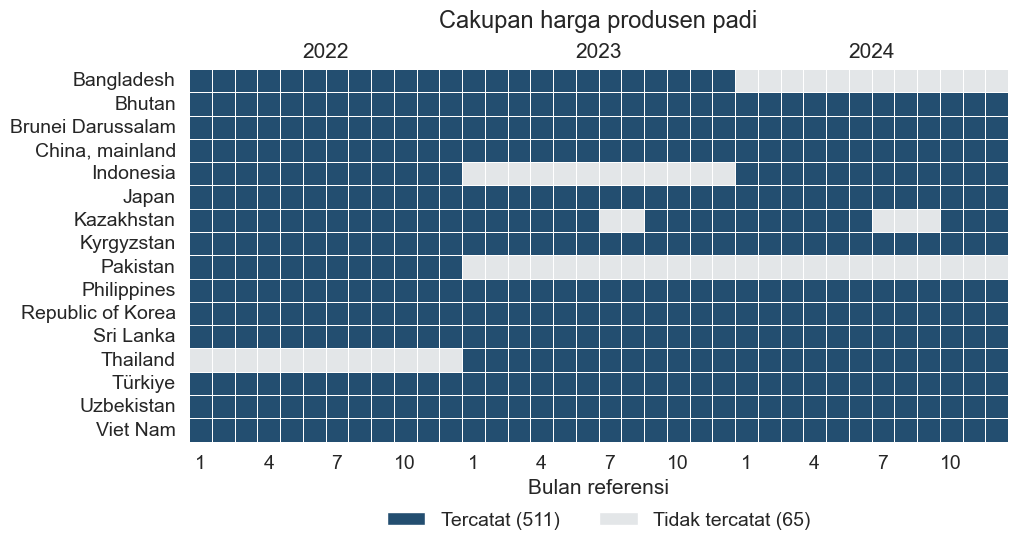

In [10]:
df_calendar['recorded'] = df_calendar[price_column].notnull().astype(int)
coverage_matrix = df_calendar.pivot(index='Country', columns='date', values='recorded')
coverage_matrix = coverage_matrix.reindex(index=country_list, columns=calendar)

plt.figure(figsize=(10.4, 5.8))
sns.heatmap(
    coverage_matrix,
    cmap=ListedColormap(['#e3e6e8', '#234e70']),
    vmin=0,
    vmax=1,
    cbar=False,
    linewidths=0.5,
    linecolor='white'
)

plt.xticks(np.arange(0, 36, 3) + 0.5, [1, 4, 7, 10] * 3, rotation=0, fontsize=14)
plt.yticks(rotation=0, fontsize=14)

for year in range(3):
    plt.text(year * 12 + 6, -0.5, str(2022 + year), ha='center', fontsize=15)

plt.title('Cakupan harga produsen padi', fontsize=17, pad=30)
plt.xlabel('Bulan referensi', fontsize=15)
plt.ylabel('')
plt.legend(
    handles=[
        Patch(facecolor='#234e70', label='Tercatat (511)'),
        Patch(facecolor='#e3e6e8', label='Tidak tercatat (65)')
    ],
    loc='upper center',
    bbox_to_anchor=(0.5, -0.14),
    ncol=2,
    frameon=False,
    fontsize=14
)
plt.tight_layout()
plt.show()


**Temuan cakupan.** Bangladesh tidak memiliki observasi terpilih pada 2024, Indonesia pada 2023, Pakistan pada 2023–2024, dan Thailand pada 2022. Kazakhstan memiliki lima bulan yang tidak tercatat. Karena itu, sampel didominasi negara dengan seri lebih lengkap dan tidak mewakili seluruh Asia.

Brunei Darussalam memiliki satu nilai harga yang sama sepanjang periode terpilih. Seri ini tetap dipertahankan karena harga tetap merupakan kondisi yang sah menurut definisi target. Penyebabnya tidak diasumsikan sebagai kesalahan pencatatan.

Level LCU tidak digabung untuk membandingkan mahal atau murahnya harga antarnegara. Analisis perubahan dan fitur menggunakan perbandingan relatif pada negara yang sama.

## 10.5 EDA perubahan harga dan nilai ekstrem

Eksplorasi yang dapat memengaruhi rancangan fitur dibatasi pada **jendela latih tahun 2022**. Return satu bulan dihitung sebagai `P(t) / P(t-1) - 1` setelah kalender dilengkapi. `fill_method=None` memastikan harga yang hilang tidak diisi otomatis.

Pagar 1,5 IQR dihitung terpisah pada return setiap negara dalam jendela tersebut. Penandaan ini merupakan pemeriksaan awal, bukan bukti bahwa suatu harga salah. Seluruh nilai tetap dipertahankan.


In [11]:
# Perubahan dihitung setelah kalender bulanan dilengkapi.
df_calendar['change_1m'] = df_calendar.groupby('Country')[price_column].pct_change(fill_method=None)
train_end = pd.Timestamp('2023-01-01')
validation_end = pd.Timestamp('2024-01-01')

df_return_train = df_calendar[
    (df_calendar['date'] < train_end)
    & df_calendar['change_1m'].notnull()
][['Country', 'date', 'change_1m']].copy()

df_return_train['change_percent'] = df_return_train['change_1m'] * 100
display(df_return_train['change_percent'].describe().rename('Perubahan bulanan (%)').to_frame())


,Perubahan bulanan (%)
count,165.000000
mean,1.982371
std,7.666928
min,-43.240364
25%,-0.393129
50%,0.495966
75%,3.565638
max,30.652308


In [12]:
# IQR diperiksa pada return tiap negara dalam jendela latih saja.
df_return_train['iqr_flag'] = False
iqr_rows = []

for country in sorted(df_return_train['Country'].unique()):
    country_mask = df_return_train['Country'] == country
    country_return = df_return_train.loc[country_mask, 'change_1m']
    q1 = country_return.quantile(0.25)
    q3 = country_return.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_flag = (country_return < lower_bound) | (country_return > upper_bound)
    df_return_train.loc[country_mask, 'iqr_flag'] = outlier_flag
    iqr_rows.append({
        'Negara': country,
        'Return tersedia': len(country_return),
        'Batas bawah (%)': lower_bound * 100,
        'Batas atas (%)': upper_bound * 100,
        'Ditandai': outlier_flag.sum()
    })

display(pd.DataFrame(iqr_rows).round(4))
print('Jumlah return yang ditandai:', df_return_train['iqr_flag'].sum())

largest_returns = df_return_train['change_1m'].abs().sort_values(ascending=False).head(5).index
display(df_return_train.loc[largest_returns, ['Country', 'date', 'change_percent', 'iqr_flag']])


,Negara,Return tersedia,Batas bawah (%),Batas atas (%),Ditandai
0,Bangladesh,11,-7.4989,15.7008,1
1,Bhutan,11,-2.2460,3.9068,2
2,Brunei Darussalam,11,0.0000,0.0000,0
3,"China, mainland",11,-2.1944,2.5856,0
4,Indonesia,11,-8.0427,11.3745,0
5,Japan,11,-0.4489,0.6271,2
6,Kazakhstan,11,-40.0029,58.7502,1
7,Kyrgyzstan,11,-10.8186,12.7636,0
8,Pakistan,11,-6.7828,13.7735,1
9,Philippines,11,-6.0025,6.7322,0


Jumlah return yang ditandai: 9


,Country,date,change_percent,iqr_flag
222,Kazakhstan,2022-07-01,-43.240364,True
223,Kazakhstan,2022-08-01,30.652308,False
227,Kazakhstan,2022-12-01,27.555152,False
219,Kazakhstan,2022-04-01,24.961304,False
401,Sri Lanka,2022-06-01,24.630515,False


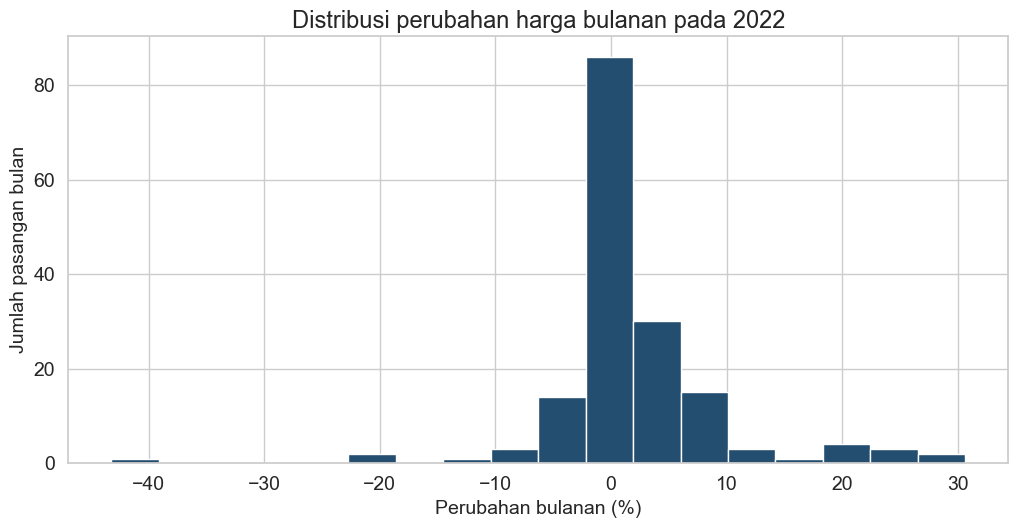

In [13]:
plt.figure(figsize=(10.4, 5.5))
sns.histplot(
    data=df_return_train,
    x='change_percent',
    bins=18,
    color='#234e70',
    edgecolor='white',
    alpha=1
)

plt.title('Distribusi perubahan harga bulanan pada 2022', fontsize=17)
plt.xlabel('Perubahan bulanan (%)', fontsize=14)
plt.ylabel('Jumlah pasangan bulan', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()


**Temuan distribusi.** Terdapat 165 pasangan bulan berturut-turut dengan return yang valid pada 2022. Median perubahan adalah **0,50%**, kuartil pertama **−0,39%**, dan kuartil ketiga **3,57%**. Rentangnya **−43,24% sampai 30,65%**. Sebagian besar perubahan berada di sekitar nol, tetapi ada beberapa perubahan besar.

Perubahan absolut terbesar terjadi di Kazakhstan pada Juli 2022, kemudian diikuti kenaikan pada Agustus. Sembilan return ditandai oleh pagar IQR per negara. Sampel tiap negara masih terbatas dan belum ada bukti kesalahan dari penerbit, sehingga nilai tersebut tidak dihapus atau diwinsorisasi. Distribusi gabungan ini menggambarkan contoh yang tersedia, bukan tingkat inflasi harga padi seluruh Asia.

## 10.6 Audit fitur, target, dan pembagian waktu

Audit berikut memeriksa apakah informasi yang tersedia cukup untuk membentuk contoh klasifikasi. Fitur hanya memakai harga sampai bulan t pada negara yang sama. Target memakai harga pada **t+1 kalender**, bukan sekadar baris berikutnya yang tersedia.

| Fitur | Definisi | Alasan penggunaan |
|---|---|---|
| `month` | Nomor bulan t, 1–12 | Menandai kalender musim secara sederhana. |
| `change_1m` | P(t) / P(t−1) − 1 | Menggambarkan perubahan satu bulan terakhir. |
| `change_3m` | P(t) / P(t−3) − 1 | Menggambarkan perubahan total tiga bulan. |
| `ratio_to_3m_mean` | P(t) / mean(P(t), P(t−1), P(t−2)) | Menunjukkan posisi harga terhadap rata-rata terbaru. |
| `volatility_3m` | Simpangan baku sampel return t, t−1, t−2, dengan `ddof=1` | Menggambarkan variasi perubahan terbaru. |

Return disimpan sebagai rasio desimal, sehingga 0,05 berarti 5%. Kelima kolom merupakan fitur turunan dari harga dan kalender, bukan lima variabel sumber yang independen. Jika ketentuan pengampu mengharuskan variabel mentah independen, rancangan perlu ditinjau kembali.


In [14]:
feature_columns = ['month', 'change_1m', 'change_3m', 'ratio_to_3m_mean', 'volatility_3m']
feature_data = []

for country in country_list:
    country_features = df_calendar[df_calendar['Country'] == country].copy()
    country_features = country_features.sort_values('date')
    current_price = country_features[price_column]
    next_price = current_price.shift(-1)

    country_features['month'] = country_features['date'].dt.month
    country_features['change_3m'] = current_price / current_price.shift(3) - 1
    country_features['ratio_to_3m_mean'] = current_price / current_price.rolling(3).mean()
    country_features['volatility_3m'] = country_features['change_1m'].rolling(3).std(ddof=1)
    country_features['target_date'] = country_features['date'] + pd.offsets.MonthBegin(1)
    country_features['next_price'] = next_price

    valid_target = current_price.notnull() & next_price.notnull()
    country_features['target'] = np.where(
        valid_target, (next_price > current_price).astype(int), np.nan
    )
    country_features['target'] = country_features['target'].astype('Int64')
    country_features['direction_actual'] = np.where(
        valid_target, np.sign(next_price - current_price), np.nan
    )
    feature_data.append(country_features)

df_features = pd.concat(feature_data, ignore_index=True)
df_complete = df_features.dropna(subset=feature_columns + ['target']).copy()
display(df_complete[['Country', 'date'] + feature_columns + ['target']].head())
print('Contoh dengan fitur dan target lengkap:', len(df_complete))


,Country,date,month,change_1m,change_3m,ratio_to_3m_mean,volatility_3m,target
3,Bangladesh,2022-04-01,4,0.010306,0.055308,1.008991,0.017136,0
4,Bangladesh,2022-05-01,5,-0.197503,-0.184013,0.862191,0.118877,1
5,Bangladesh,2022-06-01,6,0.136971,-0.078181,1.008227,0.168869,1
6,Bangladesh,2022-07-01,7,0.082305,-0.012487,1.096251,0.179422,1
7,Bangladesh,2022-08-01,8,0.013713,0.247425,1.035223,0.061760,1


Contoh dengan fitur dan target lengkap: 436


In [15]:
# Pembagian mengikuti tanggal global dan memeriksa bulan target.
df_train = df_complete[
    (df_complete['date'] < train_end)
    & (df_complete['target_date'] < train_end)
].copy()

df_validation = df_complete[
    (df_complete['date'] >= train_end)
    & (df_complete['date'] < validation_end)
    & (df_complete['target_date'] < validation_end)
].copy()

df_test = df_complete[
    (df_complete['date'] >= validation_end)
    & (df_complete['target_date'] <= pd.Timestamp('2024-12-01'))
].copy()

split_rows = []
for name, data in [('Latih', df_train), ('Validasi', df_validation), ('Uji', df_test)]:
    split_rows.append({
        'Bagian': name,
        'Baris': len(data),
        'Naik': data['target'].eq(1).sum(),
        'Tidak naik': data['target'].eq(0).sum(),
        'Negara': data['Country'].nunique(),
        'Awal fitur': data['date'].min().strftime('%Y-%m'),
        'Akhir fitur': data['date'].max().strftime('%Y-%m'),
        'Akhir target': data['target_date'].max().strftime('%Y-%m')
    })

split_summary = pd.DataFrame(split_rows)
display(split_summary)


,Bagian,Baris,Naik,Tidak naik,Negara,Awal fitur,Akhir fitur,Akhir target
0,Latih,120,78,42,15,2022-04,2022-11,2022-12
1,Validasi,145,91,54,14,2023-01,2023-11,2023-12
2,Uji,145,74,71,14,2024-01,2024-11,2024-12


In [16]:
split_coverage = country_coverage[['Negara']].copy()
split_coverage['Latih'] = split_coverage['Negara'].map(df_train['Country'].value_counts()).fillna(0).astype(int)
split_coverage['Validasi'] = split_coverage['Negara'].map(df_validation['Country'].value_counts()).fillna(0).astype(int)
split_coverage['Uji'] = split_coverage['Negara'].map(df_test['Country'].value_counts()).fillna(0).astype(int)
display(split_coverage)

audit_flow = pd.DataFrame({
    'Tahap': [
        'Observasi harga asli', 'Kerangka kalender', 'Target tidak tersedia',
        'Fitur belum lengkap', 'Contoh lengkap', 'Dikeluarkan pada batas waktu',
        'Contoh pada protokol utama'
    ],
    'Jumlah': [
        len(df_selected), len(df_features), df_features['target'].isnull().sum(),
        df_features[feature_columns].isnull().any(axis=1).sum(), len(df_complete),
        len(df_complete) - len(df_train) - len(df_validation) - len(df_test),
        len(df_train) + len(df_validation) + len(df_test)
    ]
})
display(audit_flow)


,Negara,Latih,Validasi,Uji
0,Bangladesh,8,11,0
1,Bhutan,8,11,11
2,Brunei Darussalam,8,11,11
3,"China, mainland",8,11,11
4,Indonesia,8,0,8
5,Japan,8,11,11
6,Kazakhstan,8,5,5
7,Kyrgyzstan,8,11,11
8,Pakistan,8,0,0
9,Philippines,8,11,11


,Tahap,Jumlah
0,Observasi harga asli,511
1,Kerangka kalender,576
2,Target tidak tersedia,84
3,Fitur belum lengkap,122
4,Contoh lengkap,436
5,Dikeluarkan pada batas waktu,26
6,Contoh pada protokol utama,410


**Kelayakan contoh.** Dari 576 baris kalender, 84 tidak memiliki target dan 122 memiliki set fitur yang belum lengkap. Kedua kelompok ini saling tumpang tindih, sehingga tidak boleh dijumlahkan. Setelah seluruh syarat dipenuhi, tersedia **436 contoh lengkap**. Data ini berupa panel negara-bulan, bukan satu deret 436 bulan.

Sebanyak **26 contoh** dikeluarkan dari protokol utama karena targetnya melewati batas pembagian waktu. Tersisa **410 contoh**, yaitu **120 latih, 145 validasi, dan 145 uji**. Pembagian ini adalah rancangan evaluasi retrospektif satu bulan ke depan yang diperbarui setiap bulan, bukan prediksi seluruh 2024 sekaligus pada awal tahun.

Data latih mencakup 15 negara. Thailand belum muncul pada latih 2022, tetapi hadir pada validasi dan uji. Data uji mencakup 14 negara, tanpa Bangladesh dan Pakistan. Indonesia tidak muncul pada validasi. Komposisi tersebut perlu disertakan ketika hasil model dibahas.

Kelas, fitur, parameter, atau aturan penanganan nilai ekstrem tidak dipilih berdasarkan data uji. Tabel pembagian waktu dipakai untuk memeriksa rancangan dan cakupan, bukan sebagai hasil evaluasi model.


In [17]:
# Korelasi hanya memakai contoh latih, tanpa label atau fitur dari data uji.
price_features = ['change_1m', 'change_3m', 'ratio_to_3m_mean', 'volatility_3m']
correlation_matrix = df_train[price_features].corr()
display(correlation_matrix.round(4))


,change_1m,change_3m,ratio_to_3m_mean,volatility_3m
change_1m,1.0000,0.5521,0.8557,0.1519
change_3m,0.5521,1.0000,0.7618,-0.0076
ratio_to_3m_mean,0.8557,0.7618,1.0000,0.0327
volatility_3m,0.1519,-0.0076,0.0327,1.0000


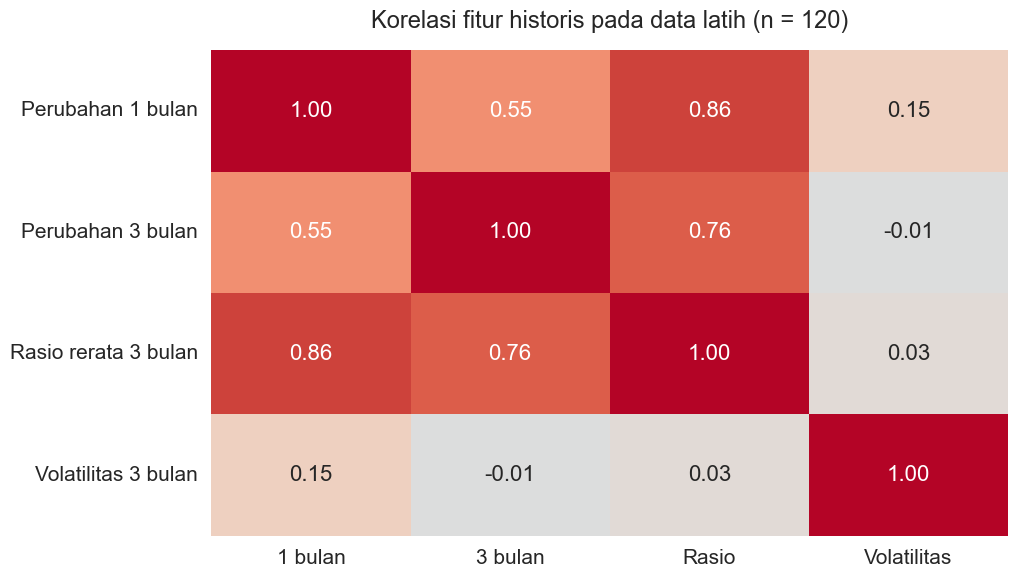

In [18]:
plt.figure(figsize=(10.4, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    cbar=False,
    annot_kws={'size': 16},
    xticklabels=['1 bulan', '3 bulan', 'Rasio', 'Volatilitas'],
    yticklabels=['Perubahan 1 bulan', 'Perubahan 3 bulan', 'Rasio rerata 3 bulan', 'Volatilitas 3 bulan']
)

plt.title('Korelasi fitur historis pada data latih (n = 120)', fontsize=17, pad=16)
plt.xticks(rotation=0, fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
plt.show()


**Temuan korelasi.** Perubahan satu bulan dan rasio terhadap rata-rata tiga bulan berkorelasi sekitar **0,856**. Perubahan tiga bulan dan rasio tersebut berkorelasi sekitar **0,762**. Sebagian fitur memuat informasi yang bertumpang tindih. Ini menjadi bahan pemeriksaan pada tahap pemilihan fitur, bukan bukti hubungan sebab-akibat atau bukti manfaat prediksi.

Nomor bulan tidak dimasukkan ke korelasi linear ini karena merupakan informasi kalender. Keputusan encoding, pengurangan fitur, atau transformasi akan ditetapkan pada tahap persiapan model menggunakan latih dan validasi.


In [19]:
class_summary = pd.DataFrame({
    'Cakupan': ['Contoh lengkap sebelum pembagian', 'Latih'],
    'Naik': [df_complete['target'].eq(1).sum(), df_train['target'].eq(1).sum()],
    'Tidak naik': [df_complete['target'].eq(0).sum(), df_train['target'].eq(0).sum()],
    'Harga tetap dalam kelas tidak naik': [
        df_complete['direction_actual'].eq(0).sum(),
        df_train['direction_actual'].eq(0).sum()
    ]
})
display(class_summary)


,Cakupan,Naik,Tidak naik,Harga tetap dalam kelas tidak naik
0,Contoh lengkap sebelum pembagian,257,179,38
1,Latih,78,42,10


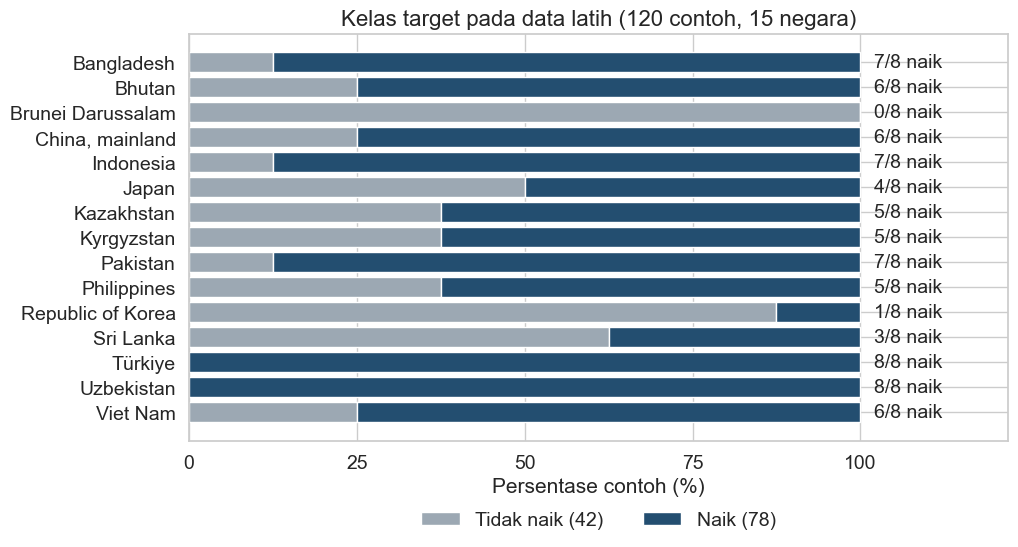

In [20]:
class_table = pd.crosstab(df_train['Country'], df_train['target'])
class_table = class_table.reindex(columns=[0, 1], fill_value=0)
class_percent = class_table.div(class_table.sum(axis=1), axis=0) * 100

plt.figure(figsize=(10.4, 5.8))
plt.barh(class_table.index, class_percent[0], color='#9ca8b3', label='Tidak naik (42)')
plt.barh(class_table.index, class_percent[1], left=class_percent[0], color='#234e70', label='Naik (78)')

for row, country in enumerate(class_table.index):
    up_count = class_table.loc[country, 1]
    total_count = class_table.loc[country].sum()
    plt.text(102, row, str(up_count) + '/' + str(total_count) + ' naik', va='center', fontsize=14)

plt.gca().invert_yaxis()
plt.xlim(0, 122)
plt.xticks([0, 25, 50, 75, 100], fontsize=14)
plt.yticks(fontsize=14)
plt.title('Kelas target pada data latih (120 contoh, 15 negara)', fontsize=16)
plt.xlabel('Persentase contoh (%)', fontsize=15)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.26), ncol=2, frameon=False, fontsize=14)
plt.tight_layout()
plt.show()


**Temuan kelas target.** Pada latih terdapat **78 contoh naik dan 42 tidak naik**, sehingga baseline mayoritas akan memprediksi kelas 1. Komposisi berbeda antarnegara dan Brunei menyumbang contoh harga tetap. Karena itu, accuracy saja belum cukup untuk menilai hasil model.

Audit seluruh 436 contoh lengkap menghasilkan **257 naik dan 179 tidak naik**. Sebanyak **38 contoh harga tetap** termasuk di dalam kelas tidak naik. Ringkasan ini menjelaskan komposisi data. Ambang utama tetap `>0` dan tidak diubah berdasarkan label uji.

## 10.7 Kesimpulan Data Understanding dan tindak lanjut

Data dapat digunakan untuk tahap analisis berikutnya setelah cakupan kalender, satuan, dan batas informasi ditetapkan. Pemeriksaan tidak menemukan duplikasi kunci atau harga tidak positif pada subset. Masalah utama adalah bulan yang tidak tercatat, cakupan negara yang tidak merata, periode pendek, serta tanggal publikasi dan riwayat revisi yang tidak tersedia.

Harga asli dipertahankan. Kolom alternatif yang kosong tidak digunakan, gap kalender tetap ditandai, dan nilai ekstrem tidak dihapus tanpa bukti kesalahan. Audit fitur menghasilkan 436 contoh lengkap dan protokol waktu menyediakan 410 contoh untuk tahap pemodelan.

Berikutnya, kelompok akan menetapkan preprocessing dan feature selection yang diperlukan, melatih Regresi Logistik berregularisasi L2 dan Random Forest sebagai pembanding, lalu menilainya terhadap kedua baseline. **Belum ada metrik hasil model.** Manfaat prediktif dan kelayakan penerapan masih perlu diuji.

Sel terakhir memeriksa angka utama dan batas informasi yang mendasari tabel serta grafik dalam laporan. Menjalankan notebook tidak membuat dataset turunan, folder hasil, atau salinan grafik baru di dalam repo. Seluruh keluaran tampil di notebook ini.


In [23]:
# Pemeriksaan akhir terhadap angka dan batas informasi yang digunakan dalam laporan.
assert df.shape == (5341, 17)
assert df['Country'].nunique() == 73
assert len(df_selected) == 511
assert len(df_calendar) == 576
assert df_calendar[price_column].isnull().sum() == 65
assert df_features['target'].isnull().sum() == 84
assert df_features[feature_columns].isnull().any(axis=1).sum() == 122
assert len(df_complete) == 436
assert [len(df_train), len(df_validation), len(df_test)] == [120, 145, 145]
assert df_complete['target'].eq(1).sum() == 257
assert df_complete['target'].eq(0).sum() == 179
assert df_complete['direction_actual'].eq(0).sum() == 38
assert len(df_return_train) == 165
assert df_return_train['iqr_flag'].sum() == 9
assert quality_summary['Jumlah'].eq(0).all()
assert df_features.loc[df_features[price_column].isnull() | df_features['next_price'].isnull(), 'target'].isnull().all()
assert (df_train['target_date'] < train_end).all()
assert (df_validation['target_date'] < validation_end).all()
assert (df_test['target_date'] <= pd.Timestamp('2024-12-01')).all()
assert np.isfinite(df_complete[feature_columns].to_numpy()).all()

display(audit_flow)


,Tahap,Jumlah
0,Observasi harga asli,511
1,Kerangka kalender,576
2,Target tidak tersedia,84
3,Fitur belum lengkap,122
4,Contoh lengkap,436
5,Dikeluarkan pada batas waktu,26
6,Contoh pada protokol utama,410
